# Premier League Match Outcome Model — Training & Evaluation

Predicts **Home win / Draw / Away win** probabilities from `matches.csv`.

**Approach**
1. The CSV has one row per team per match (each match appears twice). We keep one row per match (the home side).
2. Every feature is computed **only from matches played before** the one being predicted (no leakage).
3. Features: pre-match **Elo**, rolling form (last 5/10), venue-specific form, rest days, and home-minus-away differences.
4. Evaluation is **chronological walk-forward** (train on past seasons, test on the next) — never a random split.
5. Models are compared on **log loss** and **RPS** (both score the probabilities, not just the top pick), plus accuracy.

Run the notebooks in order: this one, then `02_epl_predict.ipynb`.

In [1]:
import warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

DATA = Path("matches.csv")          # put matches.csv next to this notebook
MODEL_PATH = Path("epl_model.joblib")

## 1. Load and sanity-check the data

In [2]:
raw = pd.read_csv(DATA, parse_dates=["date"])
print("Shape:", raw.shape)
display(raw.head())

print("\nRows per season / date range:")
display(raw.groupby("season").date.agg(["count", "min", "max"]))

home = raw[raw.venue == "Home"]
print("Home / Draw / Away share by season (home-team perspective):")
display(home.groupby("season").result.value_counts(normalize=True).unstack()[["W", "D", "L"]].round(3))

# every match should appear exactly twice (once per team)
mirror = home.merge(raw[raw.venue == "Away"], left_on=["date", "team", "opponent"],
                    right_on=["date", "opponent", "team"])
print(f"Home rows: {len(home)} | matched to an away mirror row: {len(mirror)} | missing values: {int(raw.isna().sum().sum())}")

Shape: (3140, 16)


,date,season,team,opponent,venue,gf,ga,sh,sot,opp_sh,opp_sot,fouls,corners,yellow,red,result
0,2026-08-21,2027,Arsenal,Coventry,Home,3,0,20,6,4,1,10,8,1,0,W
1,2026-08-31,2027,Arsenal,Aston Villa,Away,1,0,7,2,7,0,6,4,1,0,W
2,2026-09-06,2027,Arsenal,Chelsea,Home,2,1,16,9,13,5,13,5,2,0,W
3,2026-09-12,2027,Arsenal,Sunderland,Away,2,0,11,5,12,3,11,2,2,0,W
4,2026-09-19,2027,Arsenal,Brighton,Away,0,3,11,2,17,5,11,6,1,0,L



Rows per season / date range:


,count,min,max
season,,,
2023,760,2022-08-05,2023-05-28
2024,760,2023-08-11,2024-05-19
2025,760,2024-08-16,2025-05-25
2026,760,2025-08-15,2026-05-24
2027,100,2026-08-21,2026-09-20


Home / Draw / Away share by season (home-team perspective):


result,W,D,L
season,,,
2023,0.484,0.229,0.287
2024,0.461,0.216,0.324
2025,0.408,0.245,0.347
2026,0.426,0.274,0.300
2027,0.360,0.320,0.320


Home rows: 1570 | matched to an away mirror row: 1570 | missing values: 0


## 2. Feature engineering

The cell below writes the feature code to `epl_features.py` (so `02_epl_predict.ipynb` can reuse the exact same logic) and imports it.

- **Elo**: K=20, home advantage 60 points, goal-difference multiplier, 25% regression to the mean each new season.
- **Rolling form** per team over the last 5 and 10 matches (`shift(1)` so the current match is excluded): points, goals for/against, goal difference, shots, shots on target (and conceded), corners, fouls, cards, shot accuracy.
- **Venue form**: a team's last 5 home games (for the home side) / last 5 away games (for the away side).
- **Rest days** and games played so far.

In [3]:
%%writefile epl_features.py
"""Shared feature engineering for the EPL outcome model."""
import numpy as np
import pandas as pd

CLASSES = ["A", "D", "H"]            # fixed order -> class index 0, 1, 2
STAT_COLS = ["gf", "ga", "sh", "sot", "opp_sh", "opp_sot", "corners", "fouls", "yellow", "red"]
WINDOWS = (5, 10)
COMPACT = ["elo_diff", "d_sot_r10", "d_opp_sot_r10", "d_gd_r10"]   # final model inputs
HOME_ADV = 60


class Elo:
    def __init__(self, k=20, home_adv=HOME_ADV, base=1500, season_regress=0.25):
        self.k, self.ha, self.base, self.reg = k, home_adv, base, season_regress
        self.r = {}

    def get(self, t):
        return self.r.get(t, self.base)

    def new_season(self):
        for t in self.r:
            self.r[t] = self.r[t] * (1 - self.reg) + self.base * self.reg

    def expected_home(self, h, a):
        return 1 / (1 + 10 ** (-(self.get(h) + self.ha - self.get(a)) / 400))

    def update(self, h, a, gh, ga):
        e = self.expected_home(h, a)
        s = 1.0 if gh > ga else 0.5 if gh == ga else 0.0
        gd = abs(gh - ga)
        mult = 1.0 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
        d = self.k * mult * (s - e)
        self.r[h] = self.get(h) + d
        self.r[a] = self.get(a) - d


def add_team_features(df):
    """Per-team rolling features on the long (one row per team per match) table.

    Everything is shifted by one match, so a row only sees matches BEFORE it.
    Returns (long table, list of per-team feature columns).
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values(["date", "team"]).reset_index(drop=True)
    df["pts"] = df["result"].map({"W": 3, "D": 1, "L": 0})
    df["gd"] = df["gf"] - df["ga"]
    df["sot_ratio"] = df["sot"] / df["sh"].clip(lower=1)
    df["opp_sot_ratio"] = df["opp_sot"] / df["opp_sh"].clip(lower=1)
    base_stats = ["pts", "gd"] + STAT_COLS + ["sot_ratio", "opp_sot_ratio"]

    g = df.groupby("team", sort=False)
    for w in WINDOWS:
        for c in base_stats:
            df[f"{c}_r{w}"] = g[c].transform(lambda s: s.shift(1).rolling(w, min_periods=3).mean())
    gv = df.groupby(["team", "venue"], sort=False)
    for c in ["pts", "gd", "gf", "ga"]:
        df[f"{c}_venue5"] = gv[c].transform(lambda s: s.shift(1).rolling(5, min_periods=2).mean())
    df["rest"] = g["date"].transform(lambda s: s.diff().dt.days).clip(upper=14)
    df["n_prev"] = g.cumcount().clip(upper=38)
    feat_cols = [c for c in df.columns if "_r5" in c or "_r10" in c or "_venue5" in c] + ["rest", "n_prev"]
    return df, feat_cols


def add_match_features(m):
    """Elo-derived and home-minus-away difference features (needs elo_h / elo_a and *_h / *_a columns)."""
    m["elo_diff"] = m.elo_h - m.elo_a
    m["elo_exp"] = 1 / (1 + 10 ** (-(m.elo_diff + HOME_ADV) / 400))
    for c in ["pts", "gd", "gf", "ga", "sot", "opp_sot", "sh", "opp_sh", "corners"]:
        for w in WINDOWS:
            m[f"d_{c}_r{w}"] = m[f"{c}_r{w}_h"] - m[f"{c}_r{w}_a"]
    m["d_pts_venue5"] = m["pts_venue5_h"] - m["pts_venue5_a"]
    m["d_gd_venue5"] = m["gd_venue5_h"] - m["gd_venue5_a"]
    m["d_rest"] = m["rest_h"] - m["rest_a"]
    return m


def feature_columns(m):
    names = [c for c in m.columns if c.endswith(("_h", "_a")) and c not in ("elo_h", "elo_a")] \
            + ["elo_h", "elo_a", "elo_diff", "elo_exp"] + [c for c in m.columns if c.startswith("d_")]
    return [c for c in dict.fromkeys(names) if c not in ("gf", "ga", "result")]


def build_features(df):
    """Training table: one row per historical match.

    Returns (match table, feature names, long table, final Elo object).
    """
    df, feat_cols = add_team_features(df)
    home = df[df.venue == "Home"]
    away = df[df.venue == "Away"].rename(columns={"team": "opponent", "opponent": "team"})
    key = ["date", "team", "opponent"]
    m = home[key + ["season", "gf", "ga", "result"] + feat_cols].merge(
        away[key + feat_cols], on=key, suffixes=("_h", "_a"))
    m = m.rename(columns={"team": "home", "opponent": "away"}).sort_values("date").reset_index(drop=True)
    m["y"] = m["result"].map({"W": "H", "D": "D", "L": "A"})

    elo, last_season, eh, ea = Elo(), None, [], []
    for r in m.itertuples():
        if last_season is not None and r.season != last_season:
            elo.new_season()
        last_season = r.season
        eh.append(elo.get(r.home)); ea.append(elo.get(r.away))      # PRE-match ratings
        elo.update(r.home, r.away, r.gf, r.ga)
    m["elo_h"], m["elo_a"] = eh, ea
    m = add_match_features(m)
    return m, feature_columns(m), df, elo


def fixture_features(hist, fixtures, elo_ratings, season):
    """Features for UPCOMING fixtures, computed in bulk.

    hist      : long match history (one row per team per match)
    fixtures  : list of (home, away) or (home, away, date); default date = a week after the last match
    elo_ratings: dict team -> Elo after the last recorded match
    """
    hist = hist.copy()
    hist["date"] = pd.to_datetime(hist["date"])
    default = hist.date.max() + pd.Timedelta(days=7)
    fx = pd.DataFrame([(f[0], f[1], pd.Timestamp(f[2]) if len(f) > 2 and f[2] else default) for f in fixtures],
                      columns=["home", "away", "date"])
    known = set(hist.team)
    for t in set(fx.home) | set(fx.away):
        if t not in known:
            raise ValueError(f"Unknown team '{t}'. Known teams: {sorted(known)}")
    if (fx.date <= hist.date.max()).any():
        raise ValueError("Fixture dates must be after the last match in the history.")

    def placeholder(teams, venue, date):      # stats are dummies: features only look at earlier matches
        return pd.DataFrame([dict(date=date, season=season, team=t, opponent="?", venue=venue, gf=0, ga=0, sh=1,
                                  sot=0, opp_sh=1, opp_sot=0, fouls=0, corners=0, yellow=0, red=0, result="D")
                             for t in teams])

    parts = []
    for d, sub in fx.groupby("date"):
        feats = {}
        for venue, teams in [("Home", sub.home.unique()), ("Away", sub.away.unique())]:
            long_df, cols = add_team_features(pd.concat([hist, placeholder(teams, venue, d)], ignore_index=True))
            feats[venue] = long_df[(long_df.date == d) & (long_df.venue == venue)].set_index("team")[cols]
        rows = []
        for r in sub.itertuples():
            row = {"date": d, "home": r.home, "away": r.away}
            row.update({f"{c}_h": v for c, v in feats["Home"].loc[r.home].items()})
            row.update({f"{c}_a": v for c, v in feats["Away"].loc[r.away].items()})
            row["elo_h"], row["elo_a"] = elo_ratings.get(r.home, 1500), elo_ratings.get(r.away, 1500)
            rows.append(row)
        parts.append(pd.DataFrame(rows))
    m = add_match_features(pd.concat(parts, ignore_index=True))
    return m


Writing epl_features.py


In [4]:
from epl_features import build_features, CLASSES, COMPACT

m, FEATS, long_df, elo_final = build_features(raw)
m["y_idx"] = m["y"].map({c: i for i, c in enumerate(CLASSES)})
print(f"{len(m)} matches | {len(FEATS)} candidate features | compact model uses: {COMPACT}")
display(m[["date", "home", "away", "result", "elo_h", "elo_a", "elo_diff"] + COMPACT[1:]].tail(8).round(2))

1570 matches | 93 candidate features | compact model uses: ['elo_diff', 'd_sot_r10', 'd_opp_sot_r10', 'd_gd_r10']


,date,home,away,result,elo_h,elo_a,elo_diff,d_sot_r10,d_opp_sot_r10,d_gd_r10
1562,2026-09-19,Everton,Ipswich,W,1514.93,1415.55,99.37,1.30,-1.10,1.20
1563,2026-09-19,Newcastle,Hull,W,1516.74,1528.00,-11.26,0.25,1.50,-0.85
1564,2026-09-19,Nott'm Forest,Coventry,L,1522.73,1457.87,64.86,1.05,-0.55,3.40
1565,2026-09-19,Tottenham,Aston Villa,L,1438.47,1523.44,-84.97,0.10,-1.90,0.10
1566,2026-09-20,Fulham,Man United,D,1484.36,1576.12,-91.75,-1.50,0.30,-1.10
1567,2026-09-20,Leeds,Crystal Palace,D,1530.64,1466.38,64.26,0.10,-0.50,2.10
1568,2026-09-20,Bournemouth,Liverpool,L,1553.74,1577.37,-23.63,-0.10,-1.10,0.20
1569,2026-09-20,Man City,Sunderland,W,1684.03,1497.50,186.53,1.80,-0.70,1.70


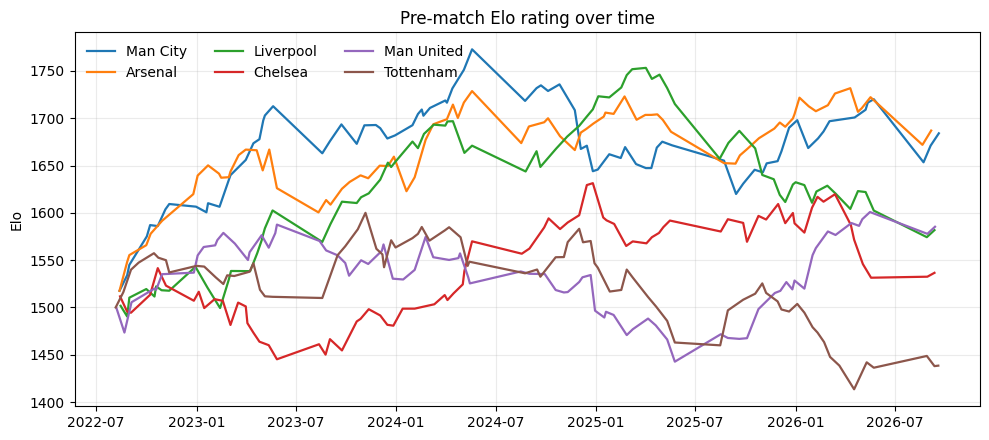

In [5]:
# Elo trajectories (home-match snapshots) for a few clubs
fig, ax = plt.subplots(figsize=(10, 4.5))
for t in ["Man City", "Arsenal", "Liverpool", "Chelsea", "Man United", "Tottenham"]:
    s = m[m.home == t]
    ax.plot(s.date, s.elo_h, label=t, lw=1.6)
ax.set_title("Pre-match Elo rating over time"); ax.set_ylabel("Elo"); ax.legend(ncol=3, frameon=False)
ax.grid(alpha=.25); plt.tight_layout(); plt.show()

## 3. Metrics and candidate models

- **Log loss** – punishes confident wrong probabilities; the main selection metric.
- **RPS** (ranked probability score) – like log loss but respects the order Away < Draw < Home.
- **Accuracy** – share of matches where the most likely outcome was right (easy to read, but ignores calibration).

Candidates: a no-skill baseline, Elo-only logistic regression, logistic regression on all features, gradient boosting, random forest, and a **compact** logistic regression (Elo + shot quality + goal difference).

In [6]:
def rps(y_idx, proba):
    onehot = np.eye(3)[y_idx]
    return np.mean(np.sum((np.cumsum(proba, 1) - np.cumsum(onehot, 1)) ** 2, axis=1) / 2)

def evaluate(name, y_idx, proba):
    return dict(model=name, n=len(y_idx),
                accuracy=accuracy_score(y_idx, proba.argmax(1)),
                log_loss=log_loss(y_idx, proba, labels=[0, 1, 2]),
                rps=rps(y_idx, proba))

def model_zoo():
    compact = make_pipeline(
        ColumnTransformer([("sel", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), COMPACT)]),
        LogisticRegression(C=0.01, max_iter=2000))
    return {
        "LogReg compact (Elo+shots)": compact,
        "LogReg (all features)": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                               LogisticRegression(C=0.05, max_iter=2000)),
        "HistGradBoost": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=200,
                                                        min_samples_leaf=40, l2_regularization=5.0, random_state=0),
        "RandomForest": make_pipeline(SimpleImputer(strategy="median"),
                                      RandomForestClassifier(n_estimators=400, min_samples_leaf=15,
                                                             max_features=0.3, n_jobs=-1, random_state=0)),
    }

## 4. Walk-forward evaluation

| Test fold | Trained on |
|---|---|
| 2025 | 2023–2024 |
| 2026 | 2023–2025 |
| 2027 (season in progress, 50 matches) | 2023–2026 |

The 2027 fold is small, so treat it as a sanity check rather than a verdict.

In [7]:
folds = [(2025, [2023, 2024]), (2026, [2023, 2024, 2025]), (2027, [2023, 2024, 2025, 2026])]
rows, oof = [], []          # oof: out-of-fold predictions of the compact model (for calibration plots)

for test_season, train_seasons in folds:
    tr, te = m[m.season.isin(train_seasons)], m[m.season == test_season]
    ytr, yte = tr.y_idx.values, te.y_idx.values

    prior = np.bincount(ytr, minlength=3) / len(ytr)
    rows.append(dict(fold=test_season, **evaluate("Baseline: class prior", yte, np.tile(prior, (len(te), 1)))))

    elo_lr = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)).fit(tr[["elo_diff"]], ytr)
    rows.append(dict(fold=test_season, **evaluate("Elo-only LogReg", yte, elo_lr.predict_proba(te[["elo_diff"]]))))

    for name, mdl in model_zoo().items():
        mdl.fit(tr[FEATS], ytr)
        p = mdl.predict_proba(te[FEATS])
        rows.append(dict(fold=test_season, **evaluate(name, yte, p)))
        if name.startswith("LogReg compact"):
            oof.append(pd.DataFrame(p, columns=CLASSES).assign(y=yte, fold=test_season))

results = pd.DataFrame(rows)
oof = pd.concat(oof, ignore_index=True)
display(results.round(4))

,fold,model,n,accuracy,log_loss,rps
0,2025,Baseline: class prior,380,0.4079,1.0860,0.2371
1,2025,Elo-only LogReg,380,0.5184,1.0001,0.2066
2,2025,LogReg compact (Elo+shots),380,0.5184,0.9980,0.2049
3,2025,LogReg (all features),380,0.4921,1.0429,0.2151
4,2025,HistGradBoost,380,0.4974,1.0984,0.2253
5,2025,RandomForest,380,0.5395,1.0147,0.2093
6,2026,Baseline: class prior,380,0.4263,1.0845,0.2278
7,2026,Elo-only LogReg,380,0.4816,1.0294,0.2095
8,2026,LogReg compact (Elo+shots),380,0.4789,1.0214,0.2068
9,2026,LogReg (all features),380,0.4711,1.0716,0.2144


fold,2025,2026,mean
model,,,
LogReg compact (Elo+shots),0.9980,1.0214,1.0097
Elo-only LogReg,1.0001,1.0294,1.0148
RandomForest,1.0147,1.0375,1.0261
LogReg (all features),1.0429,1.0716,1.0572
Baseline: class prior,1.0860,1.0845,1.0853
HistGradBoost,1.0984,1.1122,1.1053


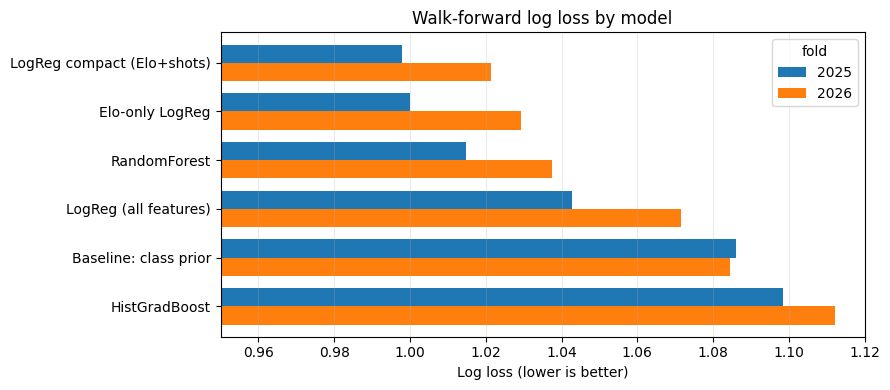

In [8]:
# Compare models on the two full seasons (2025, 2026)
pivot = results[results.fold.isin([2025, 2026])].pivot_table(index="model", columns="fold", values="log_loss")
pivot["mean"] = pivot.mean(axis=1)
pivot = pivot.sort_values("mean")
display(pivot.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
pivot[[2025, 2026]].plot.barh(ax=ax, width=.75)
ax.set_xlim(0.95, 1.12); ax.invert_yaxis()
ax.set_xlabel("Log loss (lower is better)"); ax.set_ylabel("")
ax.set_title("Walk-forward log loss by model"); ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

### Reading the comparison

- Every Elo-based model clearly beats the no-skill baseline.
- The large models (93 features) **overfit**: with ~1,000 training matches they do worse than a small, heavily regularised logistic regression.
- The compact model is only marginally ahead of Elo-only — the gap is within season-to-season noise (~380 matches per season). Elo carries most of the signal; shots-on-target-conceded adds a little.

We select the final model by mean log loss over 2025 and 2026.

In [9]:
selectable = ["LogReg compact (Elo+shots)", "LogReg (all features)", "HistGradBoost", "RandomForest"]
best_name = pivot.loc[[n for n in pivot.index if n in selectable]].index[0]
print("Selected model:", best_name)

# Where does the compact model get things wrong? (pooled 2025–2027 out-of-fold predictions)
labels = {0: "Away", 1: "Draw", 2: "Home"}
pred = oof[CLASSES].values.argmax(1)
cm = pd.crosstab(pd.Series(oof.y.map(labels), name="actual"), pd.Series(pd.Series(pred).map(labels), name="predicted"))
display(cm)
print(f"Share of matches predicted as Draw: {(pred == 1).mean():.1%} (actual draw rate: {(oof.y == 1).mean():.1%})")

Selected model: LogReg compact (Elo+shots)


predicted,Away,Home
actual,,
Away,125,137
Draw,67,146
Home,61,274


Share of matches predicted as Draw: 0.0% (actual draw rate: 26.3%)


## 5. Are the probabilities trustworthy? (calibration)

For each outcome, matches are grouped by predicted probability; a calibrated model sits on the diagonal.

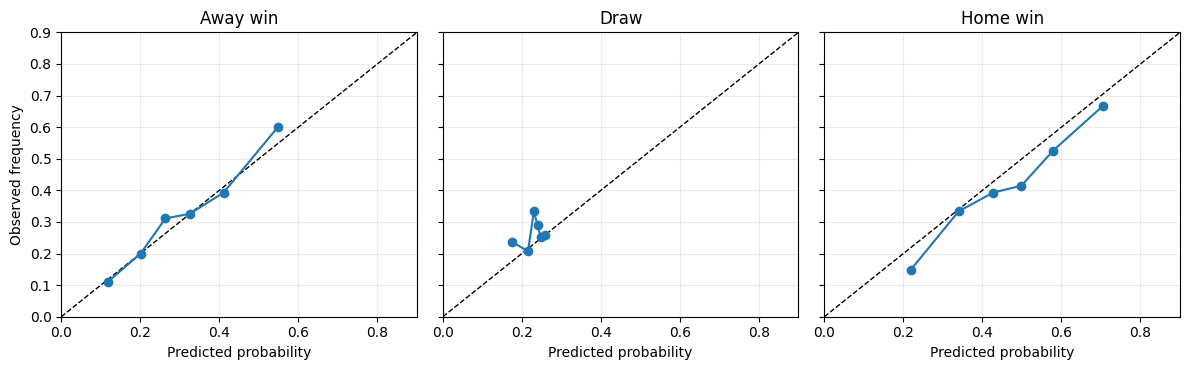

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (cls, title) in zip(axes, [("A", "Away win"), ("D", "Draw"), ("H", "Home win")]):
    d = oof[[cls, "y"]].copy()
    d["hit"] = (d.y == CLASSES.index(cls)).astype(int)
    d["bin"] = pd.qcut(d[cls], 6, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(pred=(cls, "mean"), obs=("hit", "mean"), n=("hit", "size"))
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.plot(g.pred, g.obs, "o-", color="#1f77b4")
    ax.set_title(title); ax.set_xlabel("Predicted probability"); ax.grid(alpha=.25)
    ax.set_xlim(0, .9); ax.set_ylim(0, .9)
axes[0].set_ylabel("Observed frequency")
plt.tight_layout(); plt.show()

## 6. What drives the predictions? (permutation importance)

Drop in log loss on the 2026 hold-out when a feature is shuffled (trained on 2023–2025).

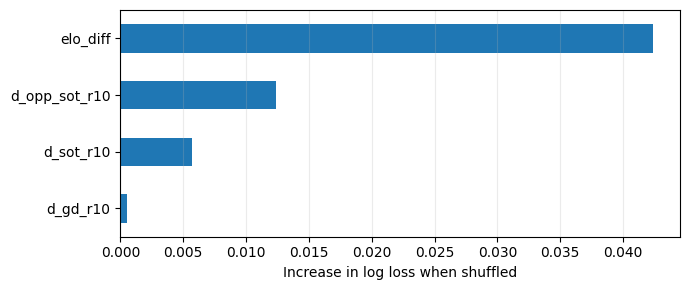

In [11]:
tr, te = m[m.season.isin([2023, 2024, 2025])], m[m.season == 2026]
twin = model_zoo()[best_name].fit(tr[FEATS], tr.y_idx.values)
pi = permutation_importance(twin, te[FEATS], te.y_idx.values, scoring="neg_log_loss", n_repeats=20, random_state=0)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False)
imp = imp[imp > 0] if (imp > 0).any() else imp.head(8)

fig, ax = plt.subplots(figsize=(7, 3))
imp.sort_values().plot.barh(ax=ax, color="#1f77b4")
ax.set_xlabel("Increase in log loss when shuffled"); ax.grid(axis="x", alpha=.25)
plt.tight_layout(); plt.show()

## 7. Fit the final model on all matches and save

The saved file bundles the fitted model, feature list, match history and final Elo ratings, so `02_epl_predict.ipynb` can score any future fixture.

In [12]:
final = model_zoo()[best_name].fit(m[FEATS], m.y_idx.values)

state = dict(
    model=final, features=FEATS, classes=CLASSES, best_name=best_name,
    long_history=long_df[["date", "season", "team", "opponent", "venue", "gf", "ga", "sh", "sot",
                          "opp_sh", "opp_sot", "fouls", "corners", "yellow", "red", "result"]],
    elo_ratings=elo_final.r, last_season=int(m.season.max()),
)
joblib.dump(state, MODEL_PATH)
results.to_csv("walk_forward_results.csv", index=False)
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size/1024:.0f} KB) — model: {best_name}")

Saved epl_model.joblib (327 KB) — model: LogReg compact (Elo+shots)
